# Ablación de nodo — bloques y cabezas (2026-08-22)

**Objetivo:** bloque B del capítulo (circuit study), punto **B.4** de `CLAUDE.md`: *"apagar (o neutralizar) un head a la vez y medir el impacto en el desempeño — importancia causal individual"*, con la referencia de Michel, Levy & Neubig (2019) *"Are Sixteen Heads Really Better than One?"* y Voita et al. (2019) *"Analyzing Multi-Head Self-Attention"*.

No adivinamos qué bloque o cabeza "es mejor" apagar — los apagamos todos, uno a la vez, y medimos la caída de accuracy. Eso es literalmente lo que hace un experimento de ablación causal: en vez de intuir cuál capa importa más, se mide.

Dos niveles de granularidad:
1. **Ablación de bloque completo**: el bloque *i* se salta por completo (ni atención ni MLP) — el residual stream pasa sin tocar. Es la versión más gruesa ("layer drop").
2. **Ablación de cabeza individual**: dentro de un bloque, se apaga (pone en cero) la salida de una sola cabeza de atención antes de concatenar y proyectar — las demás cabezas de ese bloque y el resto del modelo siguen normales. Es la versión fina que pide B.4.

Con 4 bloques × 4 cabezas = 16 combinaciones, es barato correr todo el barrido.

Corre sobre los dos checkpoints entrenados en AwA2 (`vit-with-15-epochs-AwA2` y `vit-with-15-epochs-interpretable-AwA2`) en una sola pasada, y cada gráfica se genera y guarda dos veces (una por modelo). La hipótesis de B.4 es que el baseline tiene cabezas prescindibles y otras críticas, mientras que el modelo penalizado reparte la importancia de forma más uniforme entre cabezas — comparar los dos heatmaps guardados (sección 5) es la comparación directa.

In [1]:
import json
import sys
from pathlib import Path

# Misma convención que el resto de notebooks/: vive 2 niveles bajo la raíz del proyecto.
project_root = Path.cwd().resolve().parents[1]
print(f"Project root: {project_root}")
sys.path.append(str(project_root))

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

from modules.model import ViTForClassfication
from modules.datasets import AwA2Dataset
from modules.figures import save_fig

torch.manual_seed(0)

EXPERIMENTS_DIR = project_root / "experimentation" / "experiments"
OUTPUT_DIR = EXPERIMENTS_DIR / "22082026_ablation_entropy"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Los dos modelos a comparar en todo el notebook (mismo config, misma seed de datos).
MODELS = {
    "unconstrained": "vit-15-AwA2",
    "constrained": "vit-15-constrained-AwA2",
    "constrained_rank": "vit-15-constrained_rank-AwA2",
    "entropy_l01": "vit-15-entropy_l01-s0-AwA2",
    "entropy_l001": "vit-15-entropy_l001-s0-AwA2",
    "entropy_l0001": "vit-15-entropy_l0001-s0-AwA2",
}

Project root: /home/claude/work/interpretable-transformers


/home/claude/work/ennv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/11/02 14:54:37 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /home/claude/work/ennv/lib/python3.13/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


## 1. Cargar los dos modelos

`map_location="cpu"` porque los checkpoints se guardaron desde MPS. La ablación por cabeza que armamos
abajo asume `use_faster_attention=False` (cabezas como submódulos separados, `block.attention.heads[i]`)
— lo verificamos con un `assert` para no fallar en silencio si algún día cambia.

In [2]:
def load_model(name):
    exp_dir = EXPERIMENTS_DIR / name
    with open(exp_dir / "config.json") as f:
        config = json.load(f)
    with open(exp_dir / "metrics.json") as f:
        metrics = json.load(f)
    assert not config["use_faster_attention"], (
        "Este notebook asume block.attention.heads (cabezas separadas); "
        "con use_faster_attention=True habria que adaptar la ablacion por cabeza."
    )
    model = ViTForClassfication(config)
    model.load_state_dict(torch.load(exp_dir / "model_final.pt", map_location="cpu"))
    model.eval()
    return model, config, metrics


models = {key: load_model(name) for key, name in MODELS.items()}

config = models["unconstrained"][1]
assert all(m[1] == config for m in models.values()), "Los modelos deben tener la misma arquitectura"
n_blocks = len(models["unconstrained"][0].encoder.blocks)
n_heads = config["num_attention_heads"]

for key, (_, _, metrics) in models.items():
    print(f"{key:>13} ({MODELS[key]}): accuracy de entrenamiento = {metrics['accuracy']:.4f}")
print(f"Bloques: {n_blocks}  |  cabezas por bloque: {n_heads}")

unconstrained (vit-15-AwA2): accuracy de entrenamiento = 0.2971
  constrained (vit-15-constrained-AwA2): accuracy de entrenamiento = 0.2879
constrained_rank (vit-15-constrained_rank-AwA2): accuracy de entrenamiento = 0.2973
  entropy_l01 (vit-15-entropy_l01-s0-AwA2): accuracy de entrenamiento = 0.2895
 entropy_l001 (vit-15-entropy_l001-s0-AwA2): accuracy de entrenamiento = 0.3210
entropy_l0001 (vit-15-entropy_l0001-s0-AwA2): accuracy de entrenamiento = 0.3267
Bloques: 4  |  cabezas por bloque: 4


## 2. Datos de test (AwA2)

`AwA2Dataset` usa el cache local ya construido en `data/awa2/` (ver `modules.datasets.prepare_awa2_cache`),
así que no vuelve a descargar nada.

In [3]:
dataset = AwA2Dataset(image_size=32, root=str(project_root / "data" / "awa2"))
_, testloader, classes = dataset.get_loaders(batch_size=256)
num_classes = dataset.n_classes

N_EVAL = 1000  # tamano del lote de evaluacion (CPU-friendly)
# Muestra aleatoria con semilla fija: el testset de AwA2 viene ordenado por clase, así que las primeras N
# imágenes cubrirían solo unas pocas clases.
eval_images, eval_labels = dataset.get_samples_from_indices(torch.randperm(len(dataset.testset), generator=torch.Generator().manual_seed(0))[:N_EVAL].tolist(), device="cpu", set="test")
print(f"Lote de evaluacion: {N_EVAL} imagenes de test, {num_classes} clases")

Lote de evaluacion: 1000 imagenes de test, 50 clases


## 3. Funciones de ablación

`forward_with_block_skipped`: reimplementa el forward manualmente, saltando por completo un bloque cuando `skip_block_idx` coincide (el residual stream no se toca ese paso).

`forward_with_head_ablated`: igual, pero en el bloque `ablate_layer_idx` reconstruye la atención a mano — corre cada cabeza por separado (como hace `MultiHeadAttention.forward` internamente) y pone en cero la salida de `ablate_head_idx` antes de concatenar y proyectar. El resto del bloque (las otras cabezas, el MLP) sigue intacto.

Con `skip_block_idx=None` / `ablate_layer_idx=None` ninguna de las dos toca nada — deben reproducir exactamente el forward normal del modelo. Lo verificamos abajo antes de confiar en el resto del notebook.

In [4]:
@torch.no_grad()
def forward_with_block_skipped(model, x, skip_block_idx=None):
    h = model.embedding(x)
    for i, block in enumerate(model.encoder.blocks):
        if i == skip_block_idx:
            continue  # bloque completo salteado: el residual stream pasa sin tocar
        h, _ = block(h, output_attentions=False)
    return model.classifier(h[:, 0, :])


@torch.no_grad()
def forward_with_head_ablated(model, x, ablate_layer_idx=None, ablate_head_idx=None):
    h = model.embedding(x)
    for i, block in enumerate(model.encoder.blocks):
        if i == ablate_layer_idx:
            attn_in = block.layernorm_1(h)
            head_outputs = []
            for hidx, head in enumerate(block.attention.heads):
                out, _ = head(attn_in)
                if hidx == ablate_head_idx:
                    out = torch.zeros_like(out)
                head_outputs.append(out)
            concat = torch.cat(head_outputs, dim=-1)
            attn_out = block.attention.output_projection(concat)
            attn_out = block.attention.output_dropout(attn_out)
            h = h + attn_out
            mlp_out = block.mlp(block.layernorm_2(h))
            h = h + mlp_out
        else:
            h, _ = block(h, output_attentions=False)
    return model.classifier(h[:, 0, :])


@torch.no_grad()
def accuracy_of(logits, labels):
    return (logits.argmax(dim=-1) == labels).float().mean().item()

In [5]:
# Sanity check: sin ablacion, ambas funciones deben coincidir EXACTAMENTE
# con el forward normal de cada modelo. También calculamos aquí baseline_accuracy
# por modelo, reutilizada en las secciones 4 y 5.
baseline_accuracy = {}
for key, (model, _, _) in models.items():
    with torch.no_grad():
        direct_logits, _ = model(eval_images, output_attentions=False)

    block_fn_logits = forward_with_block_skipped(model, eval_images, skip_block_idx=None)
    head_fn_logits = forward_with_head_ablated(model, eval_images, ablate_layer_idx=None, ablate_head_idx=None)

    diff_block = (direct_logits - block_fn_logits).abs().max().item()
    diff_head = (direct_logits - head_fn_logits).abs().max().item()
    assert diff_block < 1e-5 and diff_head < 1e-5, f"{key}: las reimplementaciones deben reproducir el forward normal"

    baseline_accuracy[key] = accuracy_of(direct_logits, eval_labels)
    print(f"{key:>13}: diff block={diff_block:.2e}  diff head={diff_head:.2e}  "
          f"accuracy baseline (n={N_EVAL}) = {baseline_accuracy[key]:.3f}")
print("OK - las reimplementaciones manuales son fieles al forward original, en ambos modelos.")

unconstrained: diff block=0.00e+00  diff head=0.00e+00  accuracy baseline (n=1000) = 0.323


  constrained: diff block=0.00e+00  diff head=0.00e+00  accuracy baseline (n=1000) = 0.300


constrained_rank: diff block=0.00e+00  diff head=0.00e+00  accuracy baseline (n=1000) = 0.318


  entropy_l01: diff block=0.00e+00  diff head=0.00e+00  accuracy baseline (n=1000) = 0.306


 entropy_l001: diff block=0.00e+00  diff head=0.00e+00  accuracy baseline (n=1000) = 0.342


entropy_l0001: diff block=0.00e+00  diff head=0.00e+00  accuracy baseline (n=1000) = 0.355
OK - las reimplementaciones manuales son fieles al forward original, en ambos modelos.


## 4. Ablación de bloque completo

Un bloque a la vez, saltado por completo. Si la accuracy cae poco al saltar un bloque, ese bloque es prescindible (su función la puede estar cubriendo el resto de la red); si cae mucho, es un bloque crítico.

[unconstrained] skip block 1: accuracy = 0.187  (caida vs baseline: +0.136)


[unconstrained] skip block 2: accuracy = 0.278  (caida vs baseline: +0.045)


[unconstrained] skip block 3: accuracy = 0.208  (caida vs baseline: +0.115)


[unconstrained] skip block 4: accuracy = 0.144  (caida vs baseline: +0.179)


guardado: experimentation/experiments/22082026_ablation_entropy/ablation_blocks_vit-15-AwA2.png


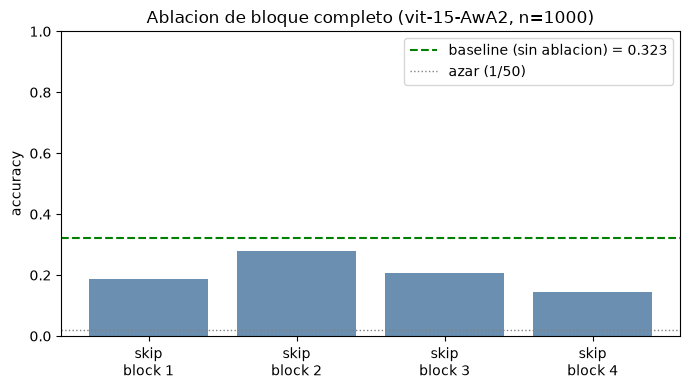

[unconstrained] Bloque mas critico (mayor caida al saltarlo): block 4



[constrained] skip block 1: accuracy = 0.174  (caida vs baseline: +0.126)


[constrained] skip block 2: accuracy = 0.271  (caida vs baseline: +0.029)


[constrained] skip block 3: accuracy = 0.215  (caida vs baseline: +0.085)


[constrained] skip block 4: accuracy = 0.126  (caida vs baseline: +0.174)
guardado: experimentation/experiments/22082026_ablation_entropy/ablation_blocks_vit-15-constrained-AwA2.png


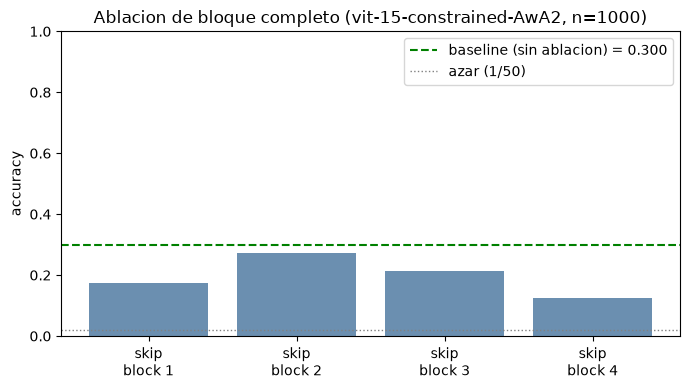

[constrained] Bloque mas critico (mayor caida al saltarlo): block 4



[constrained_rank] skip block 1: accuracy = 0.195  (caida vs baseline: +0.123)


[constrained_rank] skip block 2: accuracy = 0.268  (caida vs baseline: +0.050)


[constrained_rank] skip block 3: accuracy = 0.177  (caida vs baseline: +0.141)


[constrained_rank] skip block 4: accuracy = 0.215  (caida vs baseline: +0.103)
guardado: experimentation/experiments/22082026_ablation_entropy/ablation_blocks_vit-15-constrained_rank-AwA2.png


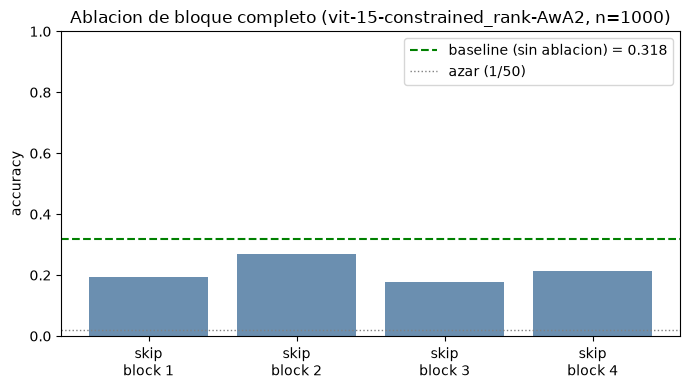

[constrained_rank] Bloque mas critico (mayor caida al saltarlo): block 3



[entropy_l01] skip block 1: accuracy = 0.173  (caida vs baseline: +0.133)


[entropy_l01] skip block 2: accuracy = 0.225  (caida vs baseline: +0.081)


[entropy_l01] skip block 3: accuracy = 0.198  (caida vs baseline: +0.108)


[entropy_l01] skip block 4: accuracy = 0.205  (caida vs baseline: +0.101)
guardado: experimentation/experiments/22082026_ablation_entropy/ablation_blocks_vit-15-entropy_l01-s0-AwA2.png


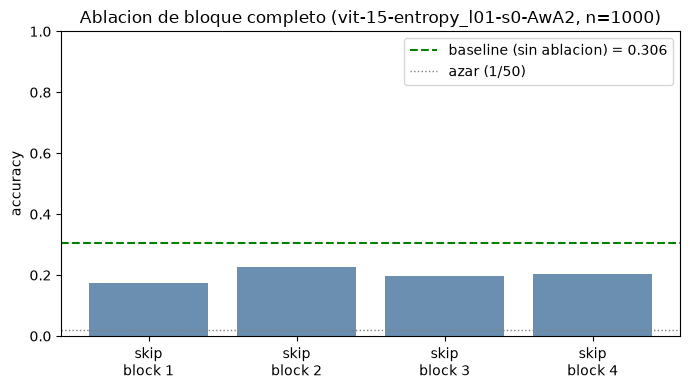

[entropy_l01] Bloque mas critico (mayor caida al saltarlo): block 1



[entropy_l001] skip block 1: accuracy = 0.173  (caida vs baseline: +0.169)


[entropy_l001] skip block 2: accuracy = 0.282  (caida vs baseline: +0.060)


[entropy_l001] skip block 3: accuracy = 0.290  (caida vs baseline: +0.052)


[entropy_l001] skip block 4: accuracy = 0.187  (caida vs baseline: +0.155)
guardado: experimentation/experiments/22082026_ablation_entropy/ablation_blocks_vit-15-entropy_l001-s0-AwA2.png


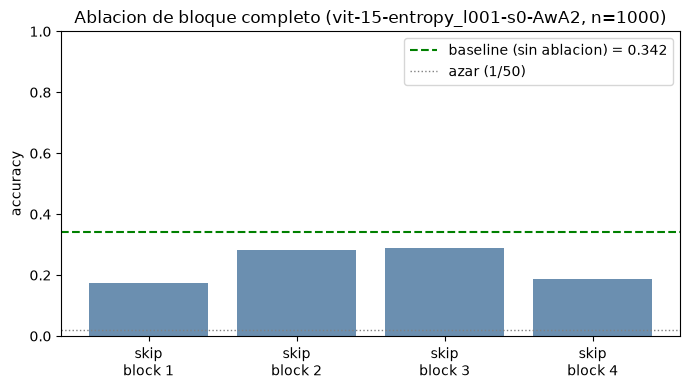

[entropy_l001] Bloque mas critico (mayor caida al saltarlo): block 1



[entropy_l0001] skip block 1: accuracy = 0.200  (caida vs baseline: +0.155)


[entropy_l0001] skip block 2: accuracy = 0.283  (caida vs baseline: +0.072)


[entropy_l0001] skip block 3: accuracy = 0.271  (caida vs baseline: +0.084)


[entropy_l0001] skip block 4: accuracy = 0.180  (caida vs baseline: +0.175)
guardado: experimentation/experiments/22082026_ablation_entropy/ablation_blocks_vit-15-entropy_l0001-s0-AwA2.png


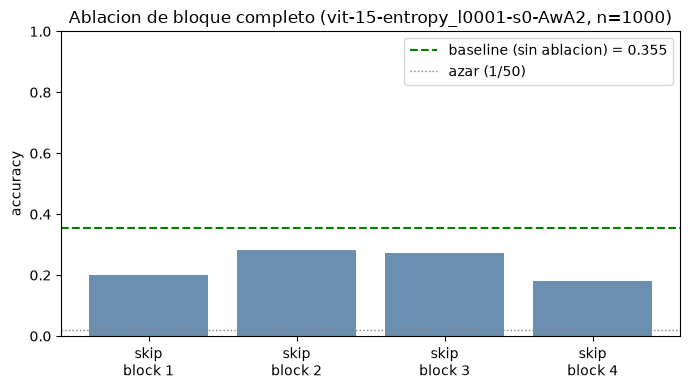

[entropy_l0001] Bloque mas critico (mayor caida al saltarlo): block 4



In [6]:
for key, (model, _, _) in models.items():
    block_accuracies = []
    for i in range(n_blocks):
        logits = forward_with_block_skipped(model, eval_images, skip_block_idx=i)
        acc = accuracy_of(logits, eval_labels)
        block_accuracies.append(acc)
        print(f"[{key}] skip block {i+1}: accuracy = {acc:.3f}  "
              f"(caida vs baseline: {baseline_accuracy[key] - acc:+.3f})")

    fig, ax = plt.subplots(figsize=(7, 4))
    labels_x = [f"skip\nblock {i+1}" for i in range(n_blocks)]
    ax.bar(labels_x, block_accuracies, color="#6b8fb0")
    ax.axhline(baseline_accuracy[key], color="green", linestyle="--", linewidth=1.5,
               label=f"baseline (sin ablacion) = {baseline_accuracy[key]:.3f}")
    ax.axhline(1 / num_classes, color="gray", linestyle=":", linewidth=1, label=f"azar (1/{num_classes})")
    ax.set_ylabel("accuracy")
    ax.set_title(f"Ablacion de bloque completo ({MODELS[key]}, n={N_EVAL})")
    ax.set_ylim(0, 1)
    ax.legend()
    plt.tight_layout()
    save_fig(fig, "ablation_blocks", OUTPUT_DIR, tag=MODELS[key], project_root=project_root)
    plt.show()

    most_critical_block = int(np.argmin(block_accuracies))
    print(f"[{key}] Bloque mas critico (mayor caida al saltarlo): block {most_critical_block + 1}\n")

## 5. Ablación de cabeza individual

Las 4×4 combinaciones de (bloque, cabeza), cada una apagada por separado. El resultado clásico de este tipo de análisis (Michel et al. 2019, Voita et al. 2019) es que unas pocas cabezas concentran casi toda la importancia y muchas otras son casi redundantes — eso es justo lo que la hipótesis de B.4 quiere contrastar entre baseline y penalizado.

guardado: experimentation/experiments/22082026_ablation_entropy/ablation_heads_vit-15-AwA2.png


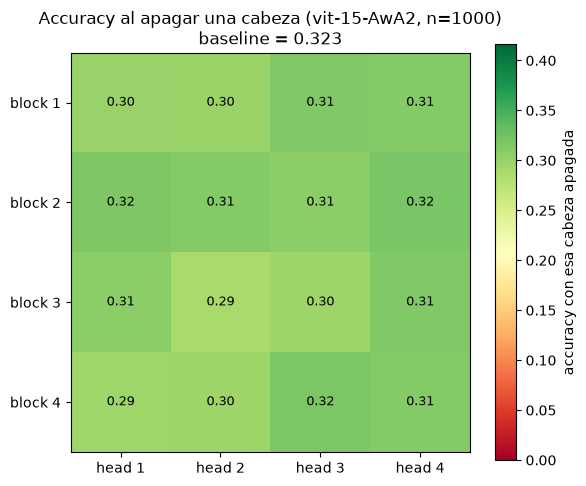

[unconstrained] Ranking de cabezas por caida de accuracy al apagarlas (mas critica primero):
  block 3, head 2: caida = +0.034  (accuracy = 0.289)
  block 4, head 1: caida = +0.028  (accuracy = 0.295)
  block 3, head 3: caida = +0.027  (accuracy = 0.296)
  block 4, head 2: caida = +0.026  (accuracy = 0.297)
  block 1, head 2: caida = +0.025  (accuracy = 0.298)
  block 1, head 1: caida = +0.023  (accuracy = 0.300)
  block 2, head 3: caida = +0.015  (accuracy = 0.308)
  block 3, head 1: caida = +0.015  (accuracy = 0.308)
  block 1, head 4: caida = +0.011  (accuracy = 0.312)
  block 2, head 2: caida = +0.010  (accuracy = 0.313)
  block 4, head 4: caida = +0.010  (accuracy = 0.313)
  block 1, head 3: caida = +0.009  (accuracy = 0.314)
  block 3, head 4: caida = +0.008  (accuracy = 0.315)
  block 2, head 1: caida = +0.007  (accuracy = 0.316)
  block 4, head 3: caida = +0.006  (accuracy = 0.317)
  block 2, head 4: caida = +0.003  (accuracy = 0.320)



guardado: experimentation/experiments/22082026_ablation_entropy/ablation_heads_vit-15-constrained-AwA2.png


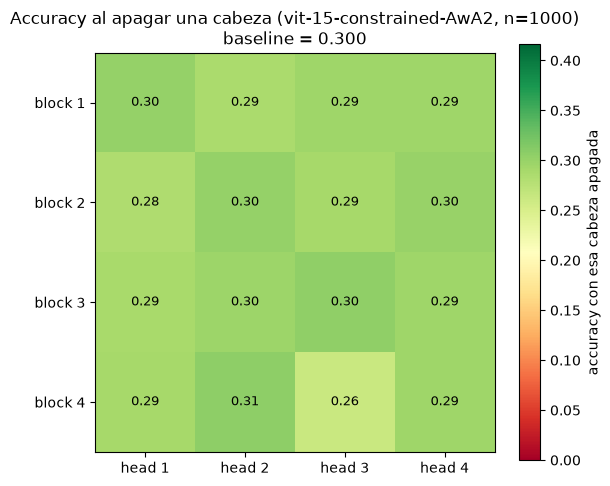

[constrained] Ranking de cabezas por caida de accuracy al apagarlas (mas critica primero):
  block 4, head 3: caida = +0.038  (accuracy = 0.262)
  block 2, head 1: caida = +0.016  (accuracy = 0.284)
  block 1, head 2: caida = +0.013  (accuracy = 0.287)
  block 3, head 1: caida = +0.012  (accuracy = 0.288)
  block 2, head 3: caida = +0.010  (accuracy = 0.290)
  block 4, head 1: caida = +0.010  (accuracy = 0.290)
  block 1, head 3: caida = +0.005  (accuracy = 0.295)
  block 1, head 4: caida = +0.005  (accuracy = 0.295)
  block 3, head 4: caida = +0.005  (accuracy = 0.295)
  block 4, head 4: caida = +0.005  (accuracy = 0.295)
  block 3, head 2: caida = +0.003  (accuracy = 0.297)
  block 2, head 4: caida = +0.000  (accuracy = 0.300)
  block 1, head 1: caida = -0.001  (accuracy = 0.301)
  block 2, head 2: caida = -0.002  (accuracy = 0.302)
  block 3, head 3: caida = -0.004  (accuracy = 0.304)
  block 4, head 2: caida = -0.006  (accuracy = 0.306)



guardado: experimentation/experiments/22082026_ablation_entropy/ablation_heads_vit-15-constrained_rank-AwA2.png


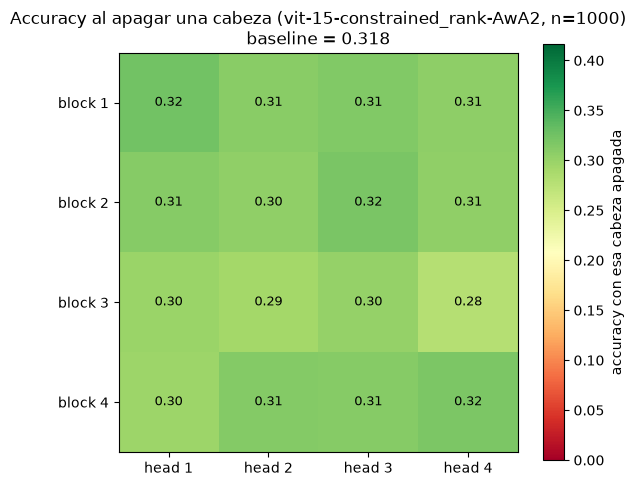

[constrained_rank] Ranking de cabezas por caida de accuracy al apagarlas (mas critica primero):
  block 3, head 4: caida = +0.039  (accuracy = 0.279)
  block 3, head 2: caida = +0.026  (accuracy = 0.292)
  block 4, head 1: caida = +0.021  (accuracy = 0.297)
  block 3, head 1: caida = +0.020  (accuracy = 0.298)
  block 3, head 3: caida = +0.016  (accuracy = 0.302)
  block 2, head 2: caida = +0.014  (accuracy = 0.304)
  block 2, head 4: caida = +0.013  (accuracy = 0.305)
  block 1, head 4: caida = +0.012  (accuracy = 0.306)
  block 1, head 2: caida = +0.009  (accuracy = 0.309)
  block 2, head 1: caida = +0.007  (accuracy = 0.311)
  block 4, head 3: caida = +0.007  (accuracy = 0.311)
  block 4, head 2: caida = +0.005  (accuracy = 0.313)
  block 1, head 3: caida = +0.004  (accuracy = 0.314)
  block 4, head 4: caida = +0.001  (accuracy = 0.317)
  block 2, head 3: caida = -0.002  (accuracy = 0.320)
  block 1, head 1: caida = -0.007  (accuracy = 0.325)



guardado: experimentation/experiments/22082026_ablation_entropy/ablation_heads_vit-15-entropy_l01-s0-AwA2.png


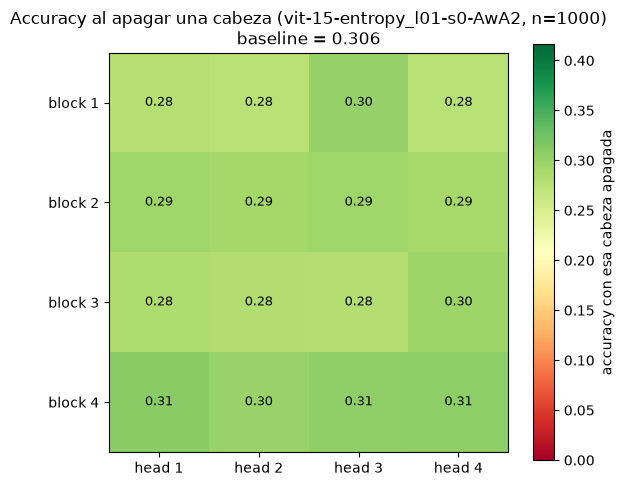

[entropy_l01] Ranking de cabezas por caida de accuracy al apagarlas (mas critica primero):
  block 1, head 2: caida = +0.030  (accuracy = 0.276)
  block 1, head 4: caida = +0.029  (accuracy = 0.277)
  block 1, head 1: caida = +0.028  (accuracy = 0.278)
  block 3, head 3: caida = +0.026  (accuracy = 0.280)
  block 3, head 2: caida = +0.024  (accuracy = 0.282)
  block 3, head 1: caida = +0.022  (accuracy = 0.284)
  block 2, head 4: caida = +0.016  (accuracy = 0.290)
  block 2, head 2: caida = +0.015  (accuracy = 0.291)
  block 2, head 1: caida = +0.011  (accuracy = 0.295)
  block 2, head 3: caida = +0.011  (accuracy = 0.295)
  block 3, head 4: caida = +0.010  (accuracy = 0.296)
  block 4, head 2: caida = +0.007  (accuracy = 0.299)
  block 1, head 3: caida = +0.005  (accuracy = 0.301)
  block 4, head 3: caida = +0.001  (accuracy = 0.305)
  block 4, head 4: caida = -0.001  (accuracy = 0.307)
  block 4, head 1: caida = -0.003  (accuracy = 0.309)



guardado: experimentation/experiments/22082026_ablation_entropy/ablation_heads_vit-15-entropy_l001-s0-AwA2.png


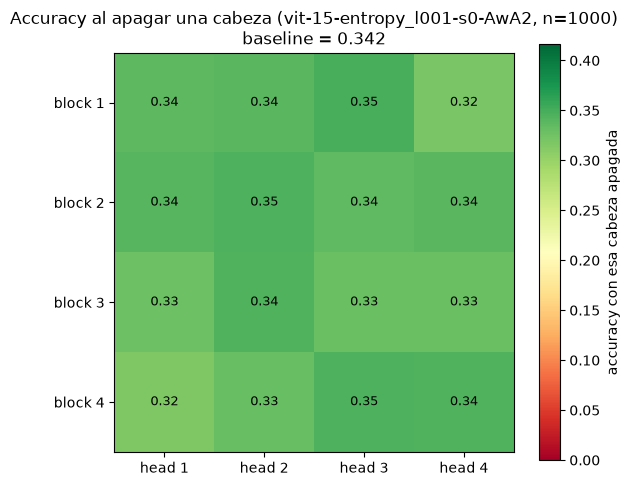

[entropy_l001] Ranking de cabezas por caida de accuracy al apagarlas (mas critica primero):
  block 4, head 1: caida = +0.026  (accuracy = 0.316)
  block 1, head 4: caida = +0.022  (accuracy = 0.320)
  block 3, head 1: caida = +0.015  (accuracy = 0.327)
  block 3, head 3: caida = +0.013  (accuracy = 0.329)
  block 3, head 4: caida = +0.013  (accuracy = 0.329)
  block 4, head 2: caida = +0.012  (accuracy = 0.330)
  block 2, head 3: caida = +0.007  (accuracy = 0.335)
  block 1, head 1: caida = +0.005  (accuracy = 0.337)
  block 1, head 2: caida = +0.004  (accuracy = 0.338)
  block 2, head 4: caida = +0.004  (accuracy = 0.338)
  block 2, head 1: caida = +0.002  (accuracy = 0.340)
  block 4, head 4: caida = -0.001  (accuracy = 0.343)
  block 3, head 2: caida = -0.002  (accuracy = 0.344)
  block 2, head 2: caida = -0.004  (accuracy = 0.346)
  block 4, head 3: caida = -0.004  (accuracy = 0.346)
  block 1, head 3: caida = -0.007  (accuracy = 0.349)



guardado: experimentation/experiments/22082026_ablation_entropy/ablation_heads_vit-15-entropy_l0001-s0-AwA2.png


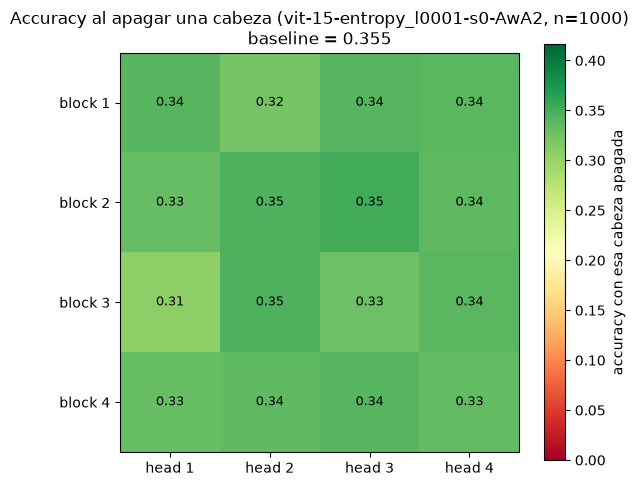

[entropy_l0001] Ranking de cabezas por caida de accuracy al apagarlas (mas critica primero):
  block 3, head 1: caida = +0.048  (accuracy = 0.307)
  block 1, head 2: caida = +0.032  (accuracy = 0.323)
  block 3, head 3: caida = +0.028  (accuracy = 0.327)
  block 4, head 1: caida = +0.025  (accuracy = 0.330)
  block 2, head 1: caida = +0.022  (accuracy = 0.333)
  block 4, head 4: caida = +0.021  (accuracy = 0.334)
  block 4, head 2: caida = +0.020  (accuracy = 0.335)
  block 2, head 4: caida = +0.018  (accuracy = 0.337)
  block 3, head 4: caida = +0.017  (accuracy = 0.338)
  block 1, head 4: caida = +0.016  (accuracy = 0.339)
  block 1, head 1: caida = +0.014  (accuracy = 0.341)
  block 1, head 3: caida = +0.014  (accuracy = 0.341)
  block 4, head 3: caida = +0.014  (accuracy = 0.341)
  block 2, head 2: caida = +0.009  (accuracy = 0.346)
  block 3, head 2: caida = +0.009  (accuracy = 0.346)
  block 2, head 3: caida = +0.003  (accuracy = 0.352)



In [7]:
head_accuracy = {}
for key, (model, _, _) in models.items():
    acc = np.zeros((n_blocks, n_heads))
    for layer_idx in range(n_blocks):
        for head_idx in range(n_heads):
            logits = forward_with_head_ablated(model, eval_images, ablate_layer_idx=layer_idx, ablate_head_idx=head_idx)
            acc[layer_idx, head_idx] = accuracy_of(logits, eval_labels)
    head_accuracy[key] = acc

# Escala de color COMPARTIDA entre modelos: 30% arriba del máximo del baseline (sin
# penalización). Con vmax por-modelo, el mismo color no significa el mismo valor entre
# las dos figuras — con un vmax compartido sí es comparable a simple vista.
vmax_shared = head_accuracy["unconstrained"].max() * 1.3

for key in MODELS:
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(head_accuracy[key], cmap="RdYlGn", vmin=0, vmax=vmax_shared)
    ax.set_xticks(range(n_heads))
    ax.set_xticklabels([f"head {h+1}" for h in range(n_heads)])
    ax.set_yticks(range(n_blocks))
    ax.set_yticklabels([f"block {l+1}" for l in range(n_blocks)])
    for l in range(n_blocks):
        for h in range(n_heads):
            ax.text(h, l, f"{head_accuracy[key][l, h]:.2f}", ha="center", va="center", fontsize=9)
    ax.set_title(f"Accuracy al apagar una cabeza ({MODELS[key]}, n={N_EVAL})\nbaseline = {baseline_accuracy[key]:.3f}")
    fig.colorbar(im, ax=ax, label="accuracy con esa cabeza apagada")
    plt.tight_layout()
    save_fig(fig, "ablation_heads", OUTPUT_DIR, tag=MODELS[key], project_root=project_root)
    plt.show()

    # Ranking de mas a menos critica (mayor caida primero)
    drops = baseline_accuracy[key] - head_accuracy[key]
    ranking = sorted(
        [(l, h, drops[l, h]) for l in range(n_blocks) for h in range(n_heads)],
        key=lambda t: -t[2],
    )
    print(f"[{key}] Ranking de cabezas por caida de accuracy al apagarlas (mas critica primero):")
    for l, h, d in ranking:
        print(f"  block {l+1}, head {h+1}: caida = {d:+.3f}  (accuracy = {head_accuracy[key][l, h]:.3f})")
    print()

In [8]:
import pandas as pd

summary_heads = pd.DataFrame({
    key: {"accuracy sin ablación": baseline_accuracy[key],
          "accuracy media al apagar 1 cabeza": head_accuracy[key].mean(),
          "std entre cabezas": head_accuracy[key].std(),
          "caída media": baseline_accuracy[key] - head_accuracy[key].mean(),
          "caída máx.": baseline_accuracy[key] - head_accuracy[key].min()}
    for key in MODELS
})
summary_heads.round(4)

,unconstrained,constrained,constrained_rank,entropy_l01,entropy_l001,entropy_l0001
accuracy sin ablación,0.3230,0.3000,0.3180,0.3060,0.3420,0.3550
accuracy media al apagar 1 cabeza,0.3069,0.2932,0.3064,0.2916,0.3354,0.3356
std entre cabezas,0.0093,0.0101,0.0110,0.0107,0.0093,0.0103
caída media,0.0161,0.0068,0.0116,0.0144,0.0066,0.0194
caída máx.,0.0340,0.0380,0.0390,0.0300,0.0260,0.0480


## Para reflexionar / siguientes pasos

- ¿Hay cabezas casi prescindibles (accuracy prácticamente igual al baseline) y otras claramente críticas? ¿En qué bloque(s) se concentran las críticas?
- ¿El bloque más crítico a nivel completo (sección 4) coincide con el bloque que tiene la cabeza más crítica (sección 5), o son distintos? (una cabeza puede ser crítica sin que su bloque entero lo sea, si las otras cabezas del mismo bloque compensan parcialmente)
- Con `N_EVAL=500` el ranking ya debería ser bastante estable, pero vale la pena subirlo antes de citar números exactos en la tesis.

La comparación real de B.4 ya está armada arriba: los dos heatmaps guardados (uno por modelo, sección 5) lado a lado — la hipótesis a contrastar es que el penalizado reparte la importancia de forma más uniforme (heatmap más "plano") que el baseline (heatmap con pocas cabezas dominantes). Complemento barato para después: contribución directa al logit por cabeza (proyectar la salida de cada cabeza, ya multiplicada por su parte de `output_projection`, directo al espacio de logits) — más rápido que la ablación porque no requiere volver a correr el forward, pero asume que no hay demasiada interacción no lineal aguas abajo.